In [1]:
import pandas as pd
import numpy as np

In [2]:
import sklearn as skl

In [3]:
import xgboost as xgb

In [4]:
import matplotlib.pyplot as plt

In [5]:
import pickle

# Loading the data

In [5]:
data_train  = pd.read_json('ECOMMERCE/train_data.json')
data_val = pd.read_json('ECOMMERCE/val_data.json')
data_test = pd.read_json('ECOMMERCE/test_data.json')

# Training model with Logistic Regression

In [6]:
OHE = skl.preprocessing.OneHotEncoder(sparse_output=False)

In [8]:
type(OHE)

sklearn.preprocessing._encoders.OneHotEncoder

In [7]:
CAT_FEATURES = ['Gender', 'Country', 'City', 'Payment_Method_Diversity', 'Signup_Quarter']

In [16]:
def Data_with_OHE(data: pd.DataFrame, ohe: skl.preprocessing._encoders.OneHotEncoder, cat_columns: list):
    X_num = data.drop(columns = cat_columns).values
    X_cat = ohe.fit_transform(data[cat_columns].astype('str').values)
    X = np.column_stack([X_num, X_cat])
    return X 

In [17]:
X_train = Data_with_OHE(data_train.drop(columns=['Churned']), OHE, CAT_FEATURES)

In [25]:
X_val = Data_with_OHE(data_val.drop(columns=['Churned']), OHE, CAT_FEATURES)

In [19]:
X_train.shape

(36125, 79)

In [20]:
y_train = data_train['Churned'].values

In [27]:
y_val = data_val['Churned'].values

In [23]:
LR_0 = skl.linear_model.LogisticRegression(max_iter =1000, tol = 0.001)

In [24]:
fit_LR_0 = LR_0.fit(X_train,y_train)

/home/rahaan/MLP/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [26]:
y_pred = fit_LR_0.predict_proba(X_val)[:,1]

In [28]:
skl.metrics.roc_auc_score(y_val, y_pred)

0.7731762413923727

It'q quite bad result, especially that with 1000 iter convervgenve is not achieved. We will try with regularization: 
we use penalty elasticnet which applies both l1 and l2 regularization (l2 regularization is default)
for elasticnet regularization there is a need to use 'saga' solver !!!

In [32]:
LR_ElasticNet = skl.linear_model.LogisticRegression(solver = 'saga',max_iter = 1000, l1_ratio = 0.5, tol = 0.001)

In [33]:
LR_ElasticNet.fit(X_train,y_train)

,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.5
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.001
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'saga'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`

In [34]:
y_pred = LR_ElasticNet.predict_proba(X_val)[:,1]

In [35]:
skl.metrics.roc_auc_score(y_val,y_pred)

0.7668708057347307

1. We didn't get inforamtion about non-convergence - so our algorithm is imporved
2. The result is not better, even slightly worse

i gonna try regularize it with 4:

In [36]:
R = [0.0, 0.25, 0.5, 0.75,1.0]

In [38]:
SCORES = []
for r in R:
    LR_MODEL = skl.linear_model.LogisticRegression(solver = 'saga',max_iter = 1000, l1_ratio = r, tol = 0.0001)
    LR_MODEL.fit(X_train, y_train)
    y_pred = LR_MODEL.predict_proba(X_val)[:,1]
    score = skl.metrics.roc_auc_score(y_val, y_pred)
    SCORES.append( (r, score) )

/home/rahaan/MLP/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/rahaan/MLP/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/rahaan/MLP/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/rahaan/MLP/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/home/rahaan/MLP/.venv/lib/python3.12/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [39]:
SCORES

[(0.0, 0.7690250172523692),
 (0.25, 0.769023580552641),
 (0.5, 0.7690219044029578),
 (0.75, 0.7690234608276636),
 (1.0, 0.7690202282532749)]

The result are practicly identical
*************************************
We gonna try to more sophisticated algorithms: 

# Training model with TreeClassfiers:

In [40]:
Tree_0 = skl.tree.DecisionTreeClassifier(random_state=40, min_samples_leaf= 5, max_depth= 50)

In [41]:
Tree_0.fit(X_train,y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",50
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",40
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples i

In [42]:
y_pred = Tree_0.predict_proba(X_val)[:,1]

In [43]:
skl.metrics.roc_auc_score(y_val, y_pred)

0.8584270101464524

We gonna try tunning max_depth and min_samples_leaf:

In [44]:
DEPTH = [5, 10, 25, 50, 75]

In [46]:
SCORES_FOR_TREES = []
for d in DEPTH:
    Tree_model = skl.tree.DecisionTreeClassifier(random_state=40, min_samples_leaf= 5, max_depth= d)
    Tree_model.fit(X_train,y_train)
    y_pred = Tree_model.predict_proba(X_val)[:,1]
    score = skl.metrics.roc_auc_score(y_val, y_pred)
    SCORES_FOR_TREES.append( (d, score) )

SCORES_FOR_TREES

max_depth = 10 gave best result 

In [48]:
LEFS_SIZE = [2, 5, 10, 15,50]

In [53]:
SCORES_FOR_LEAFS = []
for ln in LEFS_SIZE:
    Tree_model = skl.tree.DecisionTreeClassifier(random_state=40, min_samples_leaf= ln, max_depth= 10)
    Tree_model.fit(X_train,y_train)
    y_pred = Tree_model.predict_proba(X_val)[:,1]
    score = skl.metrics.roc_auc_score(y_val, y_pred)
    SCORES_FOR_LEAFS.append( (ln, score) )

In [54]:
SCORES_FOR_LEAFS

[(2, 0.8810079190889026),
 (5, 0.8896335050828041),
 (10, 0.8958272373365695),
 (15, 0.9023843348966222),
 (50, 0.9048280414095176)]

We improved it with increasing min_samples_leaf: we try ince more time with diffrent values:

In [55]:
LEFS_SIZE = [15,20,30,40]
SCORES_FOR_LEAFS = []
for ln in LEFS_SIZE:
    Tree_model = skl.tree.DecisionTreeClassifier(random_state=40, min_samples_leaf= ln, max_depth= 10)
    Tree_model.fit(X_train,y_train)
    y_pred = Tree_model.predict_proba(X_val)[:,1]
    score = skl.metrics.roc_auc_score(y_val, y_pred)
    SCORES_FOR_LEAFS.append( (ln, score) )

In [56]:
SCORES_FOR_LEAFS

[(15, 0.9023843348966222),
 (20, 0.9019618254515188),
 (30, 0.9039083739959265),
 (40, 0.9029803258339204)]

Best result is for min_samples_leaf = 30

We can check also how it works with other other criterion algorithm: by default the Gini Impurity criterion is used, other possibility is used entropy criterion:

In [57]:
Tree_model_with_entropy = skl.tree.DecisionTreeClassifier(criterion='entropy', random_state=40, min_samples_leaf= 30, max_depth= 10)
Tree_model_with_entropy.fit(X_train,y_train)
y_pred_with_entropy = Tree_model_with_entropy.predict_proba(X_val)[:,1]
score_for_entropy = skl.metrics.roc_auc_score(y_val, y_pred_with_entropy)

In [58]:
score_for_entropy

0.9014745447936636

The result is quite similar  

# Training model with xgboost

### Defining DMatrices:

DMatrix as native data type used by xgb booster
- they can handle categorical data but such data need to be set as dtye 'category' and should be not be float

In [6]:
data_train.dtypes

Age                                int64
Membership_Years                 float64
Login_Frequency                    int64
Session_Duration_Avg             float64
Pages_Per_Session                float64
Cart_Abandonment_Rate            float64
Wishlist_Items                     int64
Total_Purchases                  float64
Average_Order_Value              float64
Days_Since_Last_Purchase           int64
Discount_Usage_Rate              float64
Returns_Rate                     float64
Email_Open_Rate                  float64
Customer_Service_Calls             int64
Product_Reviews_Written            int64
Social_Media_Engagement_Score    float64
Mobile_App_Usage                 float64
Lifetime_Value                   float64
Credit_Balance                     int64
Gender                               str
Country                              str
City                                 str
Payment_Method_Diversity         float64
Signup_Quarter                       str
Churned         

Our model has 4 categorical features:
- Gender (str)
- Country (str)
- Cities(str)
- Payment_Method_Diversity (flaot64) - here we need to change to str before changing to category type (otherwise DMatrix would have a problem with interpreting it)
- Signup_Quarte - str

Splitting into features + target

In [6]:
X_train = data_train.iloc[:,:-1]
y_train = data_train['Churned']
X_val = data_val.iloc[:,:-1]
y_val = data_val['Churned']
X_test = data_test.iloc[:,:-1]
y_test = data_test['Churned']

In [7]:
# Function defining DMatrix
def To_DM_with_cat(dt: pd.DataFrame,y: pd.Series, cat_feat: list) -> xgb.DMatrix:
    dt[cat_feat] = dt[cat_feat].astype('str').astype('category')
    DM = xgb.DMatrix(dt, label = y, enable_categorical=True)
    return DM

In [8]:
CAT_FEATURES = ['Gender', 'Country', 'City', 'Payment_Method_Diversity', 'Signup_Quarter']

- DMatrix can handle pd.DataFrames type
- when 'category' type it's neccessary to set : enable_categorical = True (default = False )
- creating DMatrix we specified what are labels (target) and what are features. Binary clasfication should have binary values (0,1)


In [9]:
DM_train = To_DM_with_cat(X_train, y_train,CAT_FEATURES) 
DM_val = To_DM_with_cat(X_val, y_val, CAT_FEATURES)
DM_test = To_DM_with_cat(X_test, y_test, CAT_FEATURES)

*******************************

## Training xgboost

### First model

Paarameters include:
1. objective: method of calssification - here we set just binary:logistic
2. tree_method: hist is most recommended
Important features
3. max_depth: very important feature - very deep tree can easily overfit data and be hardly generalize
4. gamma: is one of the regularazitaion parameters, it controls when spliting is sufficently proffitable. default setting is 0 - the biggest $\gamma$ the more conservative spliting will be, generally speaking gamma also prevent from overfitting
5. min_child_weight: is realted to hessian (2nd derivatives of loss fucntion). Parameter control when splitting can be accepted, is sum of hessians is lower for min_child_weight, the split is rejected. Default is 1
6. subsample: can control the number of samples used to training one tree, samples are chosen randomly, default nr is 1(so there we use the whole set)

In [23]:
par0 = {
    'objective': 'binary:logistic',
    'tree_method': 'hist',
    
    'max_depth': 6,
    'gamma': 0.0,
    'min_child_weight':1,
    'subsample':1,
    
    'n_jobs': 8,
    'eta': 0.3,
    'eval_metric': 'auc',
    'verbosity': 1,
    'seed':1
}

xgb pkg allows to trace a training of the model on variety ways: 
- setting watchlist we can see how auc score behave during training
- verbose_eval controls the number of prints with auc values (for example if we set 5 we will see auc every 5 steps)

In [13]:
watchlist = [(DM_train, 'train'), (DM_val, 'eval')] 

In [36]:
type(watchlist)

list

In [17]:
import time

In [24]:
start = time.perf_counter()
training_track = {}
tree0 = xgb.train(par0, DM_train, num_boost_round=100 ,evals = watchlist, verbose_eval=False, evals_result=training_track)

end = time.perf_counter()

In [25]:
print(end-start)

0.5831280170004902


Prediction

In [27]:
y_pred0 = tree0.predict(DM_val)
skl.metrics.roc_auc_score(y_val, y_pred0)

0.9184890803637149

Plotting

<Axes: title={'center': 'Feature importance'}, xlabel='Importance score', ylabel='Features'>

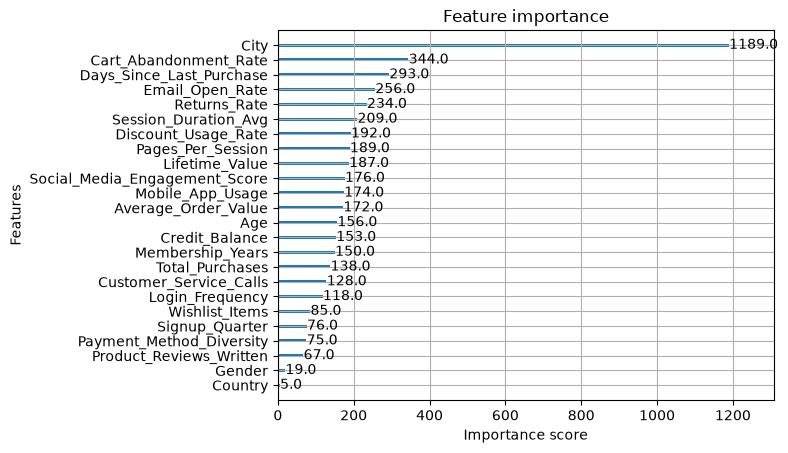

In [28]:
fig=plt.figure()
xgb.plot_importance(tree0, ax=plt.gca())

In [31]:
col = ['iter', 'train_auc', 'val_auc']

In [32]:
def Plot_track(track: dict, columns: list) -> None:
    columns = ['iter', 'train_auc', 'val_auc']
    train_aucs = list(track['train'].values())[0]
    val_aucs = list(track['eval'].values())[0]
    
    df_scores = pd.DataFrame(
        list(zip(
            range(1, len(train_aucs) + 1),
            train_aucs,
            val_aucs
            )), columns=columns)
    
    plt.plot(df_scores.iter, df_scores.train_auc, label='train')
    plt.plot(df_scores.iter, df_scores.val_auc, label='val')
    plt.legend()

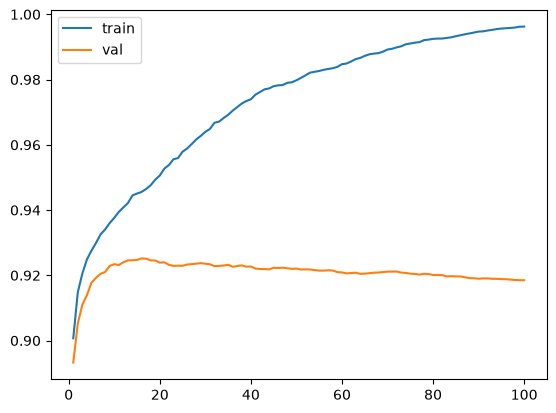

In [33]:
Plot_track(training_track, col)

## Tuning model

### 1. Max_depth tuning

In [34]:
T_RANGE = [2,4,6,10,15]

In [10]:
def Training_XGB(parameters: list , Train_set: xgb.DMatrix, watch_list: list):
        training_track = {}
        tree_model = xgb.train(parameters, Train_set, num_boost_round=75,evals=watch_list, verbose_eval=False, evals_result=training_track)
        return tree_model, training_track

In [40]:
TRACK = []
RESULTS = []
for T in T_RANGE:
        
        par_max_depth = {
        'objective': 'binary:logistic',
        'tree_method': 'hist',
    
        'max_depth': T,
        'gamma': 0.0,
        'min_child_weight':1,
        'subsample':1,
    
        'n_jobs': 8,
        'eta': 0.3,
        'eval_metric': 'auc',
        'verbosity': 1,
        'seed':1
        }
    
        trees, tracks = Training_XGB(par_max_depth,DM_train,watchlist)
        y_pred = trees.predict(DM_val)
        score = skl.metrics.roc_auc_score(y_val, y_pred)
        ret = (par_max_depth, score)
        TRACK.append(tracks)
        RESULTS.append(ret)

In [41]:
TRACK

[{'train': OrderedDict([('auc',
                [0.7345212832068975,
                 0.8153954389795557,
                 0.8406488835390832,
                 0.8661728914144948,
                 0.8561559070253525,
                 0.8652089988709422,
                 0.8687151116460917,
                 0.8826570687418936,
                 0.8837699595965252,
                 0.8989860556690834,
                 0.9010405770325374,
                 0.9043622166857953,
                 0.906723061706277,
                 0.9076792430646922,
                 0.9086607134525843,
                 0.9100599912288069,
                 0.9114926797861321,
                 0.9121294814731872,
                 0.9122396812511081,
                 0.9127700081180192,
                 0.9128681969599418,
                 0.9137690731461523,
                 0.914941813397531,
                 0.9158219988989353,
                 0.915971590665211,
                 0.916224714236393,
          

In [42]:
for x in RESULTS:
    print(x[0]['max_depth'], x[1])

2 0.927677852651118
4 0.9228453335274475
6 0.9205121930311443
10 0.918368397586536
15 0.9205479309368862


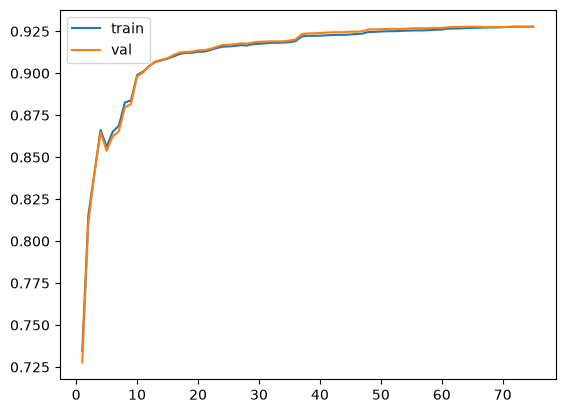

In [46]:
Plot_track(TRACK[0],col)

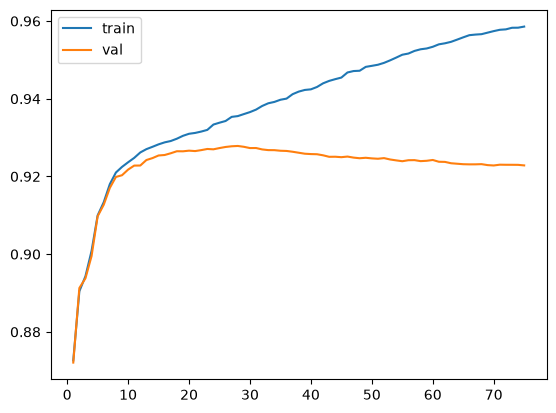

In [47]:
Plot_track(TRACK[1],col)

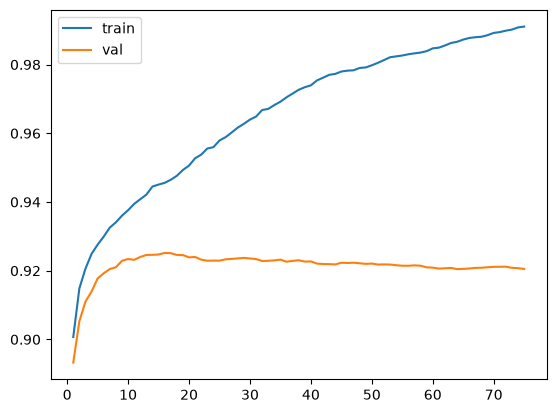

In [48]:
Plot_track(TRACK[2],col)

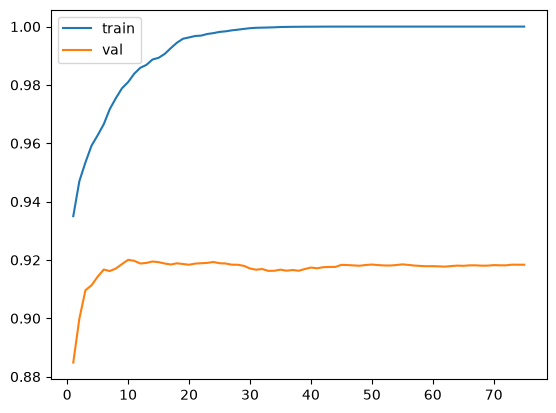

In [49]:
Plot_track(TRACK[3],col)

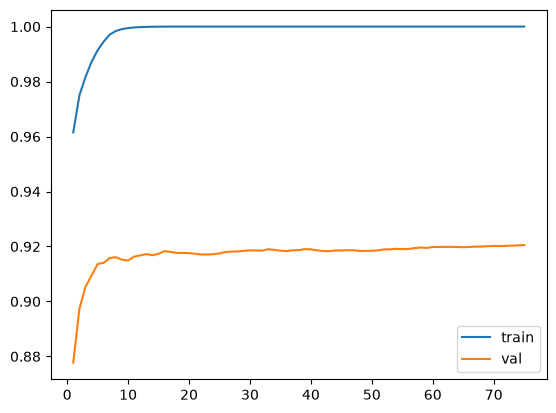

In [50]:
Plot_track(TRACK[4],col)

$$\textbf{For depth greater than 2 models very well fit to train set, but for all models prediction on calidational set are very similar}$$
I gonna choose depth = 2, more accurate prediction on train set is sign of overfitting 

### Min_child_weigth tuning:

In [53]:
CHILD_RANGE = [1,2,5,10,15]

In [54]:
TRACK = []
RESULTS = []
for child_w in CHILD_RANGE:
        
        par_max_depth = {
        'objective': 'binary:logistic',
        'tree_method': 'hist',
    
        'max_depth': 2,
        'gamma': 0.0,
        'min_child_weight':child_w,
        'subsample':1,
    
        'n_jobs': 8,
        'eta': 0.3,
        'eval_metric': 'auc',
        'verbosity': 1,
        'seed':1
        }
    
        trees, tracks = Training_XGB(par_max_depth,DM_train,watchlist)
        y_pred = trees.predict(DM_val)
        score = skl.metrics.roc_auc_score(y_val, y_pred)
        ret = (par_max_depth, score)
        TRACK.append(tracks)
        RESULTS.append(ret)

In [56]:
for x in RESULTS:
    print(x[0]['min_child_weight'], round(x[1],4))

1 0.9277
2 0.9275
5 0.9277
10 0.9278
15 0.9273


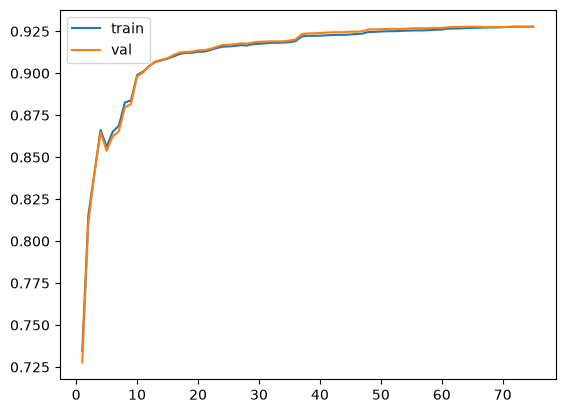

In [62]:
Plot_track(TRACK[0],col) # all plots looks similar

$$\textbf{Results for all child weights differ at fourth place after dot, so we can safly saty at min child weight eqaul to one}$$

### Subsample tuning:

In [65]:
SUBSAMPLE_RANGE = [0.5,0.75,0.9,1]

In [66]:
TRACK = []
RESULTS = []
for subs in SUBSAMPLE_RANGE:
        
        par_max_depth = {
        'objective': 'binary:logistic',
        'tree_method': 'hist',
    
        'max_depth': 2,
        'gamma': 0.0,
        'min_child_weight':1,
        'subsample':subs,
    
        'n_jobs': 8,
        'eta': 0.3,
        'eval_metric': 'auc',
        'verbosity': 1,
        'seed':1
        }
    
        trees, tracks = Training_XGB(par_max_depth,DM_train,watchlist)
        y_pred = trees.predict(DM_val)
        score = skl.metrics.roc_auc_score(y_val, y_pred)
        ret = (par_max_depth, score)
        TRACK.append(tracks)
        RESULTS.append(ret)

In [68]:
for x in RESULTS:
    print(x[0]['subsample'], round(x[1],4))

0.5 0.9252
0.75 0.9249
0.9 0.9257
1 0.9277


$$\textbf{Best fit has been obtained for full subsample, still with little differences}$$

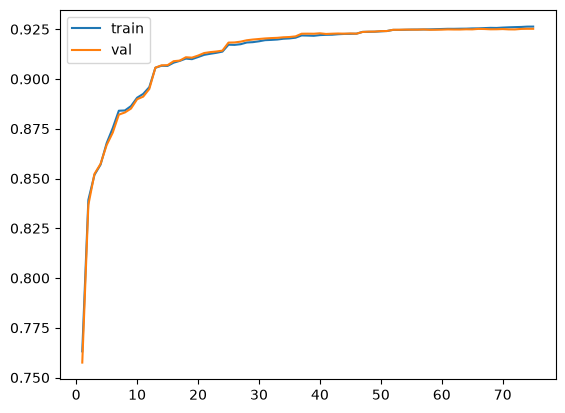

In [69]:
Plot_track(TRACK[0],col)

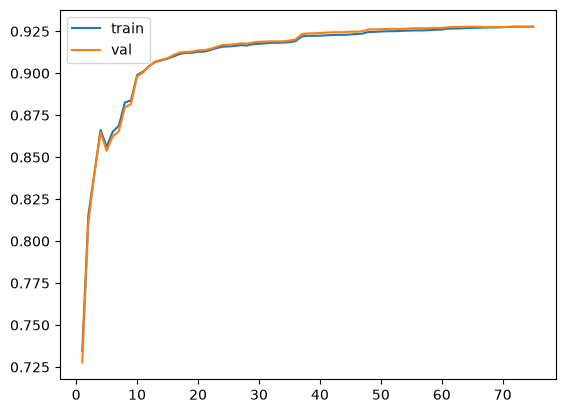

In [71]:
Plot_track(TRACK[3],col)

### Gamma tuning

In [72]:
Γ_RANGE = [0.0, 0.5, 1.0, 5.0, 10.0]

In [73]:
TRACK = []
RESULTS = []
for γ in Γ_RANGE:
        
        par_max_depth = {
        'objective': 'binary:logistic',
        'tree_method': 'hist',
    
        'max_depth': 2,
        'gamma': γ,
        'min_child_weight':1,
        'subsample':1,
    
        'n_jobs': 8,
        'eta': 0.3,
        'eval_metric': 'auc',
        'verbosity': 1,
        'seed':1
        }
    
        trees, tracks = Training_XGB(par_max_depth,DM_train,watchlist)
        y_pred = trees.predict(DM_val)
        score = skl.metrics.roc_auc_score(y_val, y_pred)
        ret = (par_max_depth, score)
        TRACK.append(tracks)
        RESULTS.append(ret)

In [74]:
for x in RESULTS:
    print(x[0]['subsample'], round(x[1],4))

1 0.9277
1 0.9277
1 0.9277
1 0.9277
1 0.9277


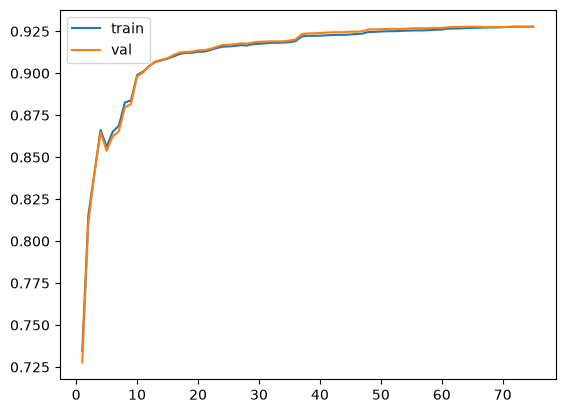

In [75]:
Plot_track(TRACK[0],col)

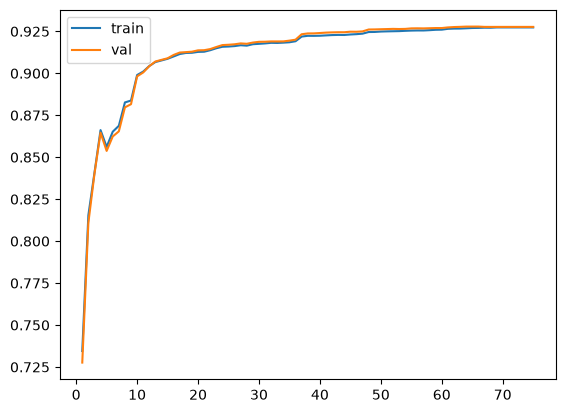

In [78]:
Plot_track(TRACK[4],col)

$$\textbf{As one can note there is no differences with fiffrent values of gamma parameter, so we stay with default values }$$

The final parameters are

In [ ]:
xgb_final_params = par_max_depth = {
        'objective': 'binary:logistic',
        'tree_method': 'hist',
    
        'max_depth': 2,
        'gamma': 0.0,
        'min_child_weight':1,
        'subsample':1,
    
        'n_jobs': 8,
        'eta': 0.3,
        'eval_metric': 'auc',
        'verbosity': 1,
        'seed':1
        }

COMMENT: I decided to not tune eta parameter cuz it controls learining rate, my models were trained quite fast (<1s) and they were convergent so there is not need to change it

## Final model

In [11]:
xgb_final_params = par_max_depth = {
        'objective': 'binary:logistic',
        'tree_method': 'hist',
    
        'max_depth': 2,
        'gamma': 0.0,
        'min_child_weight':1,
        'subsample':1,
    
        'n_jobs': 8,
        'eta': 0.3,
        'eval_metric': 'auc',
        'verbosity': 1,
        'seed':1
        }

In [14]:
model, tack = Training_XGB(xgb_final_params, DM_train, watchlist)

In [15]:
type(model)

xgboost.core.Booster

In [44]:
data_val.dtypes

Age                                int64
Membership_Years                 float64
Login_Frequency                    int64
Session_Duration_Avg             float64
Pages_Per_Session                float64
Cart_Abandonment_Rate            float64
Wishlist_Items                     int64
Total_Purchases                  float64
Average_Order_Value              float64
Days_Since_Last_Purchase           int64
Discount_Usage_Rate              float64
Returns_Rate                     float64
Email_Open_Rate                  float64
Customer_Service_Calls             int64
Product_Reviews_Written            int64
Social_Media_Engagement_Score    float64
Mobile_App_Usage                 float64
Lifetime_Value                   float64
Credit_Balance                     int64
Gender                               str
Country                              str
City                                 str
Payment_Method_Diversity         float64
Signup_Quarter                       str
Churned         

In [61]:
data_val.iloc[0,: -1] ## Series we get and after all we lost dtypes!!

Age                                   18
Membership_Years                     1.9
Login_Frequency                       13
Session_Duration_Avg                34.3
Pages_Per_Session                    9.0
Cart_Abandonment_Rate               64.8
Wishlist_Items                         4
Total_Purchases                     13.0
Average_Order_Value               171.68
Days_Since_Last_Purchase              21
Discount_Usage_Rate                  4.0
Returns_Rate                         7.7
Email_Open_Rate                     11.9
Customer_Service_Calls                 5
Product_Reviews_Written                5
Social_Media_Engagement_Score       33.5
Mobile_App_Usage                    26.5
Lifetime_Value                   1958.07
Credit_Balance                      2217
Gender                              Male
Country                               UK
City                             Glasgow
Payment_Method_Diversity             1.0
Signup_Quarter                        Q2
Name: 0, dtype: 

In [53]:
singular_dt = data_val.iloc[[0],: -1]

In [54]:
data_val.iloc[[0],: -1]

,Age,Membership_Years,Login_Frequency,Session_Duration_Avg,Pages_Per_Session,Cart_Abandonment_Rate,Wishlist_Items,Total_Purchases,Average_Order_Value,Days_Since_Last_Purchase,...,Product_Reviews_Written,Social_Media_Engagement_Score,Mobile_App_Usage,Lifetime_Value,Credit_Balance,Gender,Country,City,Payment_Method_Diversity,Signup_Quarter
0,18,1.9,13,34.3,9.0,64.8,4,13.0,171.68,21,...,5,33.5,26.5,1958.07,2217,Male,UK,Glasgow,1.0,Q2


In [55]:
singular_dt[CAT_FEATURES] = singular_dt[CAT_FEATURES].astype('str').astype('category')
singular_DM = xgb.DMatrix(singular_dt, enable_categorical=True)

In [63]:
model.predict(singular_DM)

array([0.90257096], dtype=float32)

In [60]:
float(model.predict(singular_DM)[0])

0.9025709629058838

# Saving model

In [24]:
file_name = 'model_01.bin'

In [26]:
with open(file_name, 'wb') as f_out:
    pickle.dump(model, f_out)